In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv("uber.csv")
print(df.head())
print(df.info())
print(df.describe())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [3]:
# drop unnecessary columns
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

# missing values
print(df.isnull().sum())
df = df.dropna()

# convert pickup_datetime to datetime and extract features
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["dayofweek"] = df["pickup_datetime"].dt.dayofweek
df = df.drop(columns=["pickup_datetime"])

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [4]:
# Haversine formula: distance (km) between pickup and drop-off points
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df["pickup_longitude"], df["pickup_latitude"],
                              df["dropoff_longitude"], df["dropoff_latitude"])
print(df[["fare_amount", "distance_km"]].head())

   fare_amount  distance_km
0          7.5     1.683323
1          7.7     2.457590
2         12.9     5.036377
3          5.3     1.661683
4         16.0     4.475450


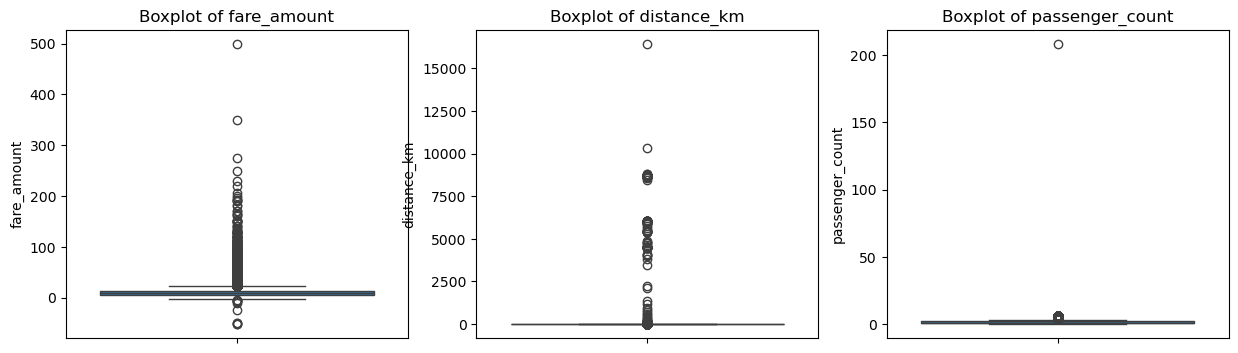

In [5]:
cols = ["fare_amount", "distance_km", "passenger_count"]
plt.figure(figsize=(15, 4))
for i, c in enumerate(cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[c])
    plt.title("Boxplot of " + c)
plt.show()

In [6]:
# Remove invalid / outlier values
print("Rows before:", len(df))
df = df[(df["fare_amount"] > 0) & (df["fare_amount"] < 100)]
df = df[(df["distance_km"] > 0) & (df["distance_km"] < 100)]
df = df[(df["passenger_count"] > 0) & (df["passenger_count"] <= 6)]
df = df[(df["pickup_latitude"].between(-90, 90)) & (df["dropoff_latitude"].between(-90, 90))]
df = df[(df["pickup_longitude"].between(-180, 180)) & (df["dropoff_longitude"].between(-180, 180))]
print("Rows after :", len(df))

Rows before: 199999
Rows after : 193115


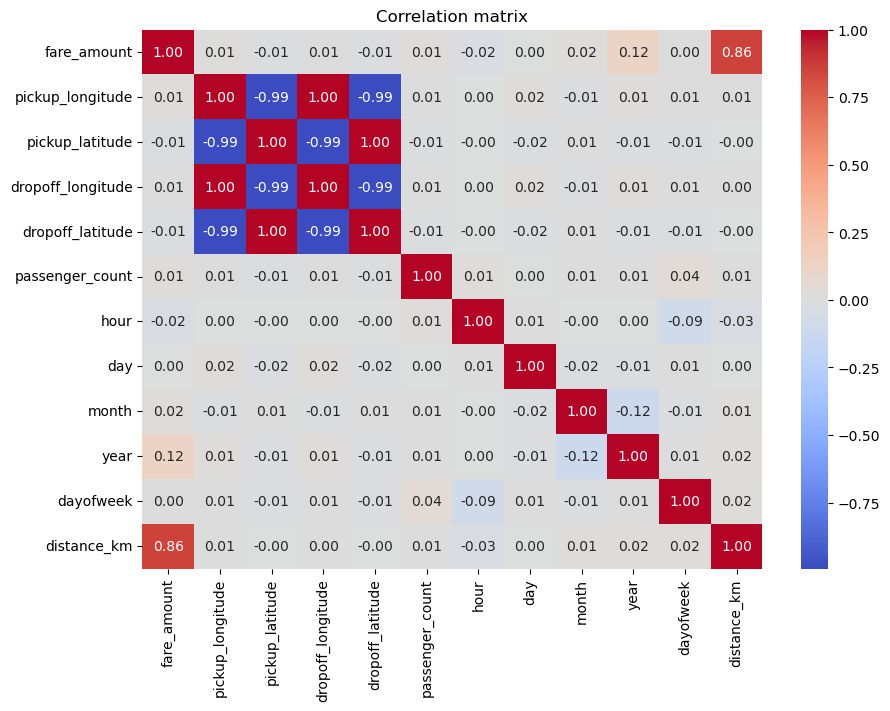

fare_amount          1.000000
distance_km          0.858430
year                 0.122964
month                0.024618
passenger_count      0.013812
pickup_longitude     0.012213
dropoff_longitude    0.010766
dayofweek            0.004948
day                  0.000644
dropoff_latitude    -0.008968
pickup_latitude     -0.009011
hour                -0.020570
Name: fare_amount, dtype: float64


In [7]:
corr = df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()
print(corr["fare_amount"].sort_values(ascending=False))

In [16]:
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [14]:
def evaluate(name, y_true, y_pred):
    return {"Model": name,
            "R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mean_squared_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

results = pd.DataFrame([evaluate("Linear Regression", y_test, y_pred_lr),
                        evaluate("Random Forest", y_test, y_pred_rf)])
print(results)

               Model        R2       MAE        MSE      RMSE
0  Linear Regression  0.765955  2.251916  19.829870  4.453074
1      Random Forest  0.865388  1.747404  11.405247  3.377166


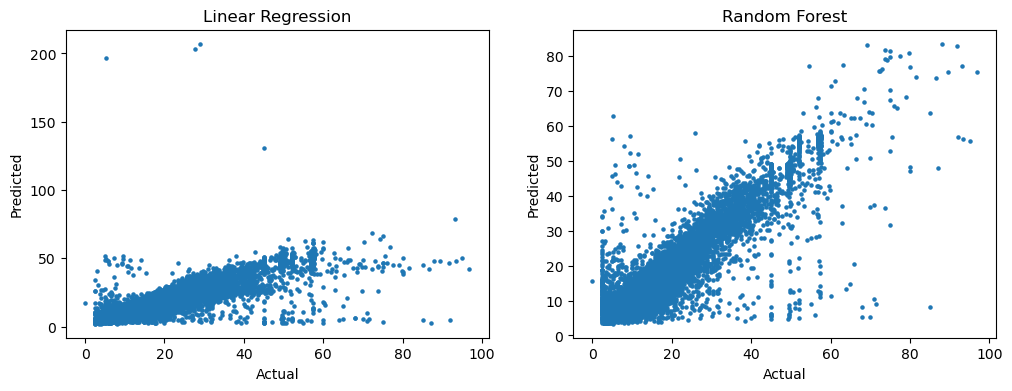

In [13]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.scatter(y_test, y_pred_lr, s=5); plt.title("Linear Regression"); plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.subplot(1, 2, 2); plt.scatter(y_test, y_pred_rf, s=5); plt.title("Random Forest"); plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.show()